<h3 align="center" style="color:rgb(1, 126, 250);"><b>BIVARIATE & MULTIVARIATE ANALYSIS</b></h3>

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

housing = pd.read_csv("housing.csv")

In [3]:
target = "median_house_value"

numerical_features = [
    "longitude",
    "latitude",
    "housing_median_age",
    "total_rooms",
    "total_bedrooms",
    "population",
    "households",
    "median_income"
]

categorical_features = ["ocean_proximity"]

In [4]:
housing.shape

(20640, 10)

In [5]:
target

'median_house_value'

In [8]:
import seaborn as sns
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

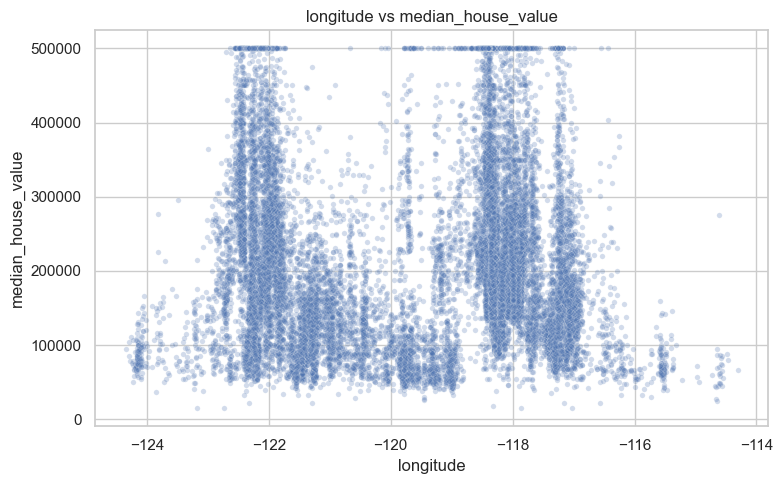

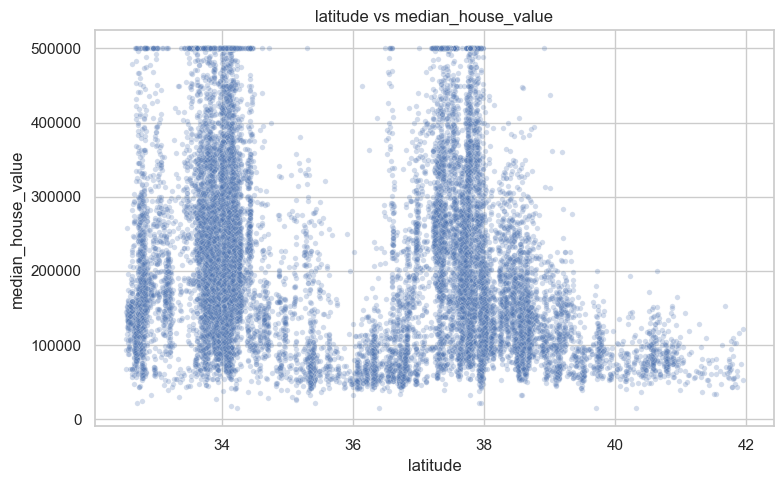

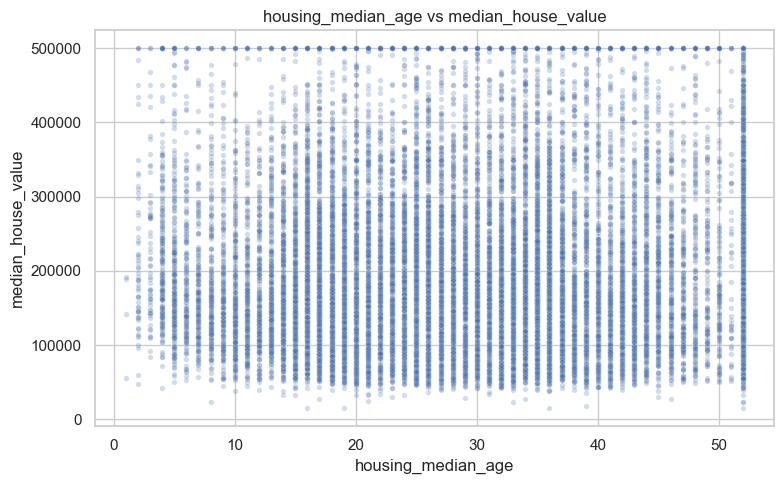

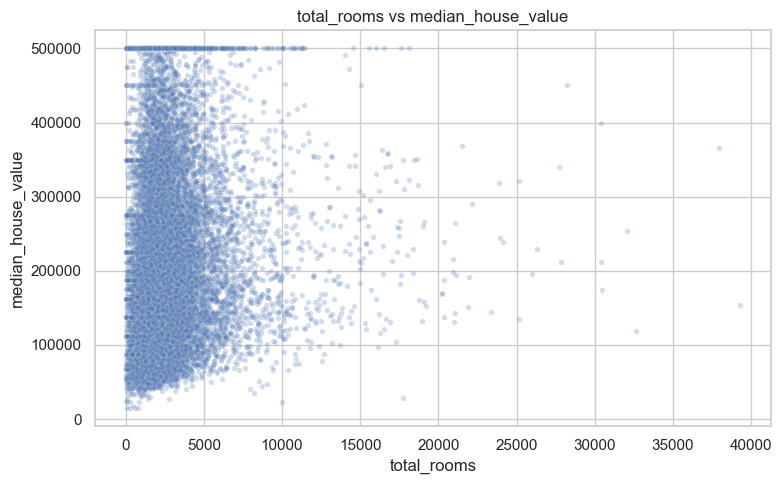

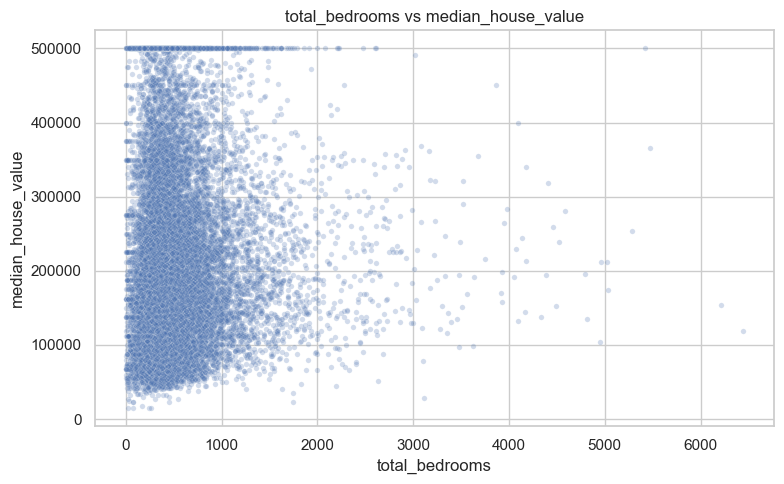

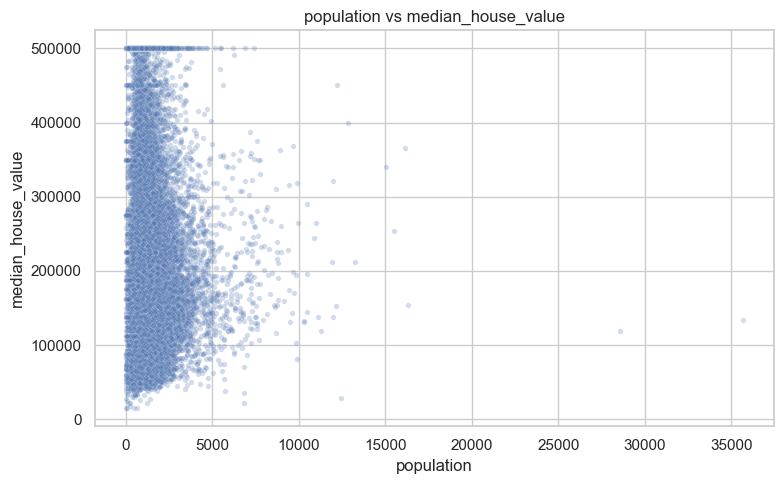

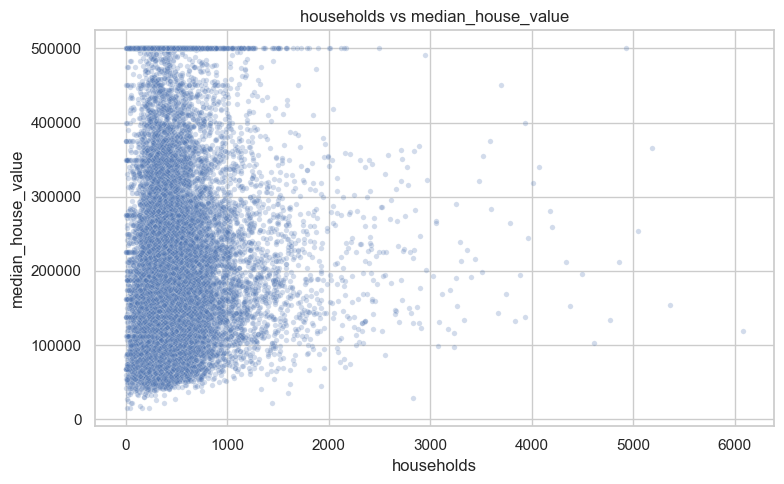

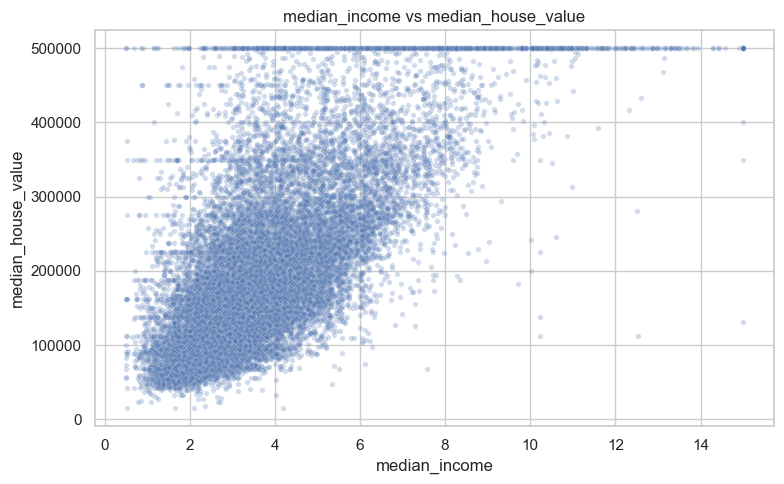

In [9]:
for feature in numerical_features:
    plt.figure(figsize=(8, 5))

    sns.scatterplot(
        data=housing,
        x=feature,
        y=target,
        alpha=0.25,
        s=15
    )

    plt.title(f"{feature} vs {target}")
    plt.tight_layout()
    plt.show()

Correlation with median_house_value:
median_income         0.688075
total_rooms           0.134153
housing_median_age    0.105623
households            0.065843
total_bedrooms        0.049686
population           -0.024650
longitude            -0.045967
latitude             -0.144160
Name: median_house_value, dtype: float64


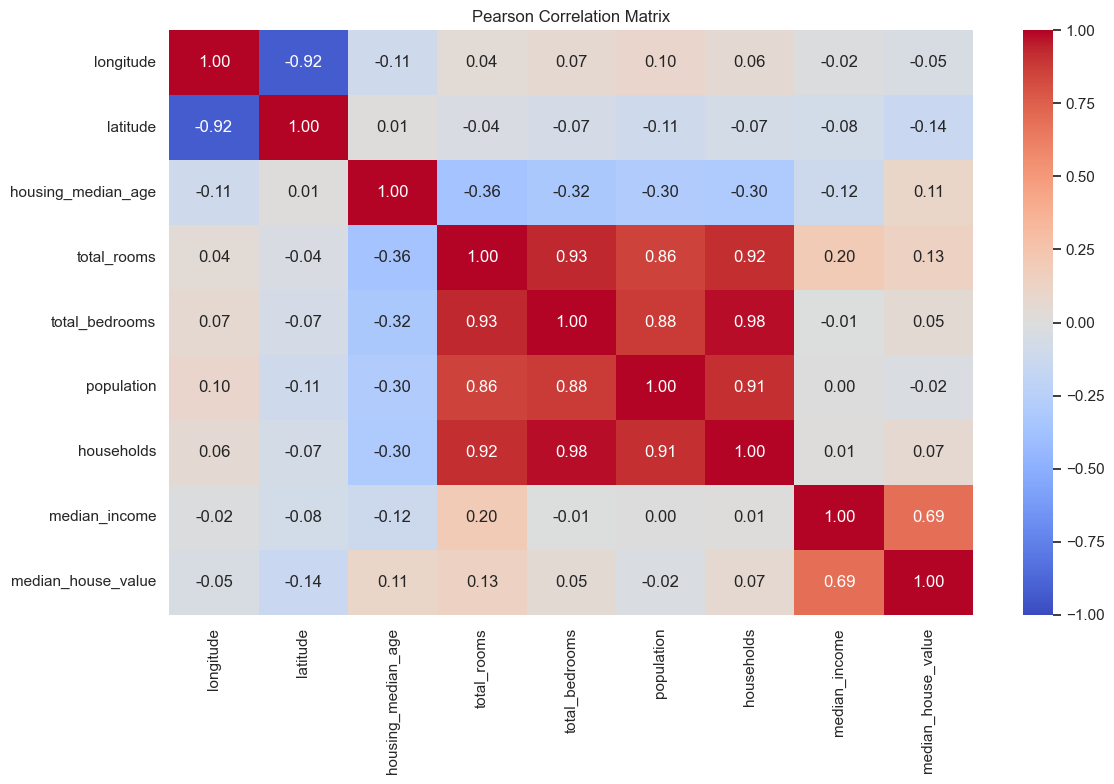

In [10]:
correlation_columns = numerical_features + [target]

corr_matrix = housing[correlation_columns].corr(method="pearson")

print("Correlation with median_house_value:")
print(
    corr_matrix[target]
    .drop(target)
    .sort_values(ascending=False)
)

# Heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Pearson Correlation Matrix")
plt.tight_layout()
plt.show()

                 count           mean    median            std       min  \
ocean_proximity                                                            
ISLAND               5  380440.000000  414700.0   80559.561816  287500.0   
NEAR BAY          2290  259212.311790  233800.0  122818.537064   22500.0   
NEAR OCEAN        2658  249433.977427  229450.0  122477.145927   22500.0   
<1H OCEAN         9136  240084.285464  214850.0  106124.292213   17500.0   
INLAND            6551  124805.392001  108500.0   70007.908494   14999.0   

                      max  
ocean_proximity            
ISLAND           450000.0  
NEAR BAY         500001.0  
NEAR OCEAN       500001.0  
<1H OCEAN        500001.0  
INLAND           500001.0  


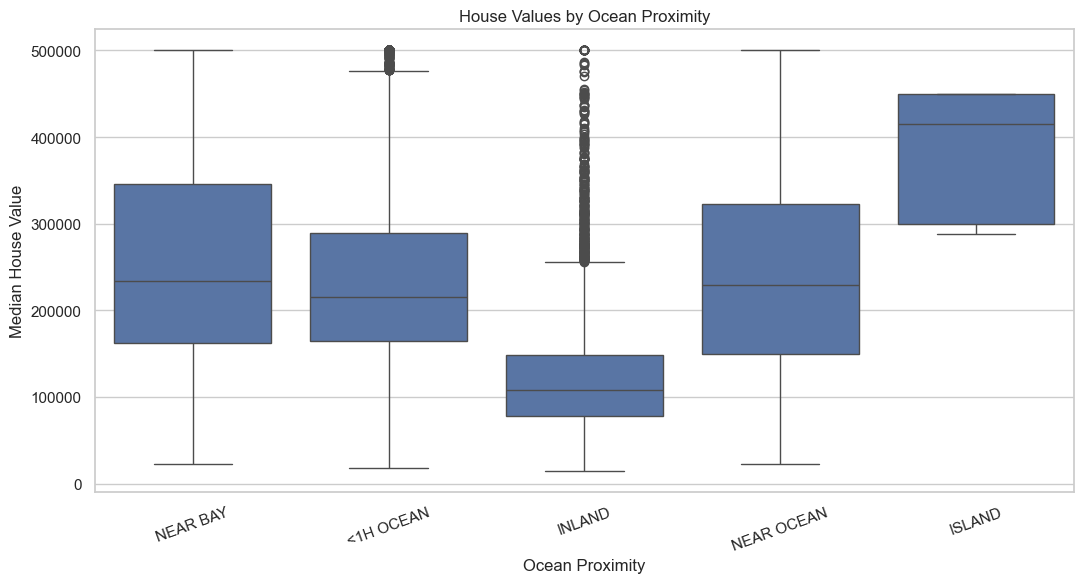

In [11]:
category_summary = (
    housing.groupby("ocean_proximity")[target]
      .agg(["count", "mean", "median", "std", "min", "max"])
      .sort_values("median", ascending=False)
)

print(category_summary)

plt.figure(figsize=(11, 6))

sns.boxplot(
    data=housing,
    x="ocean_proximity",
    y=target
)

plt.title("House Values by Ocean Proximity")
plt.xlabel("Ocean Proximity")
plt.ylabel("Median House Value")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

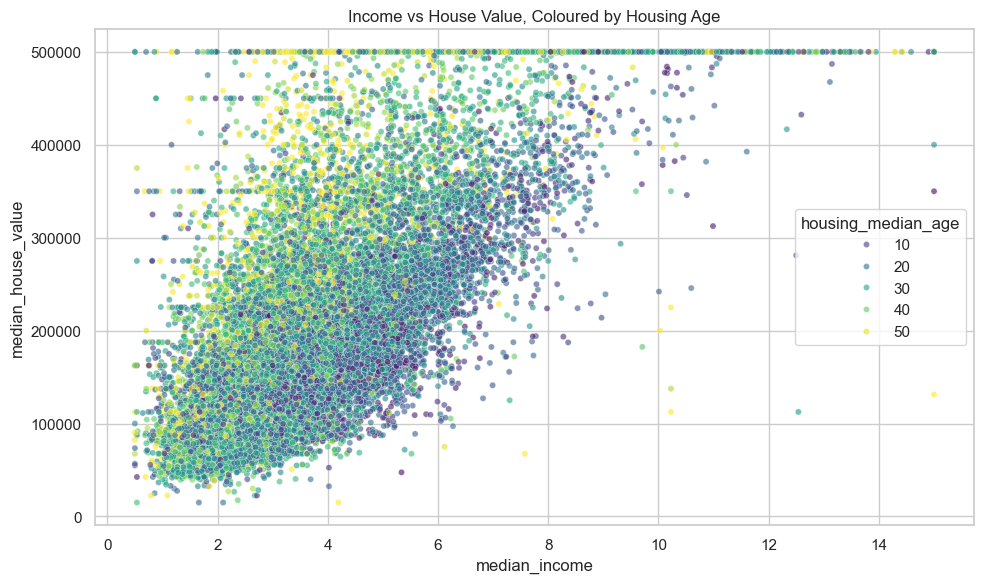

In [12]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=housing,
    x="median_income",
    y=target,
    hue="housing_median_age",
    palette="viridis",
    alpha=0.6,
    s=20
)

plt.title("Income vs House Value, Coloured by Housing Age")
plt.tight_layout()
plt.show()

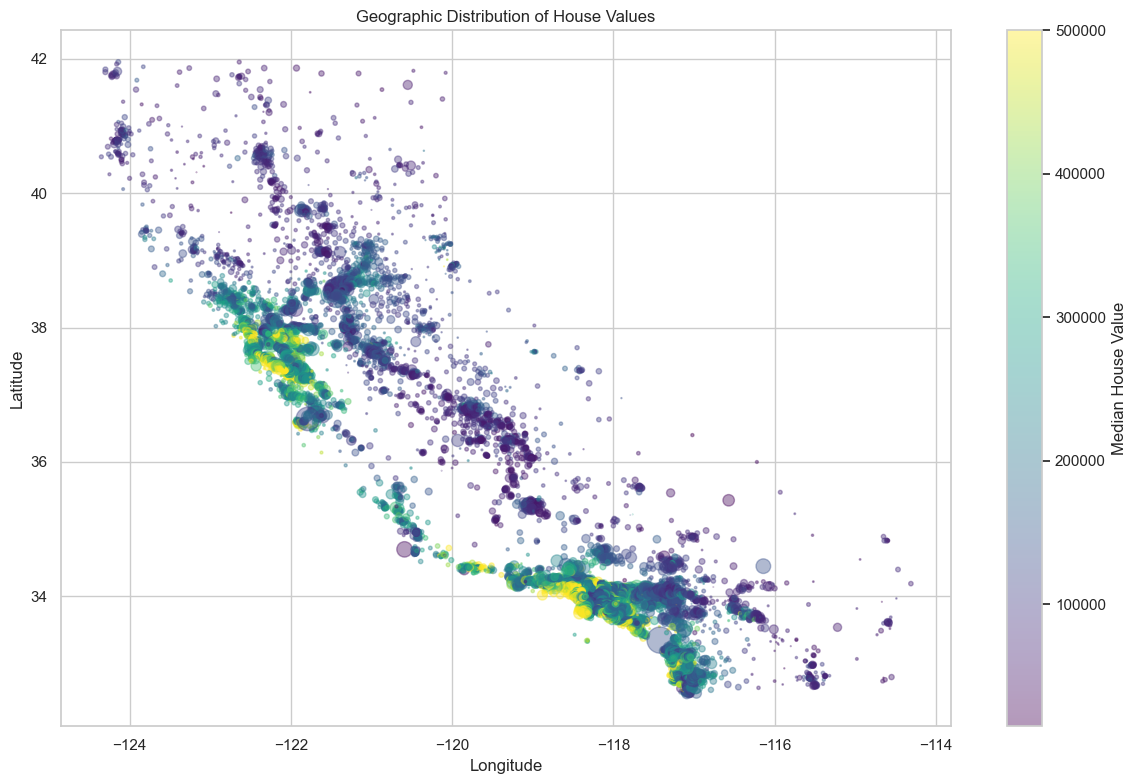

In [13]:
plt.figure(figsize=(12, 8))

scatter = plt.scatter(
    housing["longitude"],
    housing["latitude"],
    c=housing[target],
    s=housing["population"] / 100,
    alpha=0.4,
    cmap="viridis"
)

plt.colorbar(scatter, label="Median House Value")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Geographic Distribution of House Values")
plt.tight_layout()
plt.show()

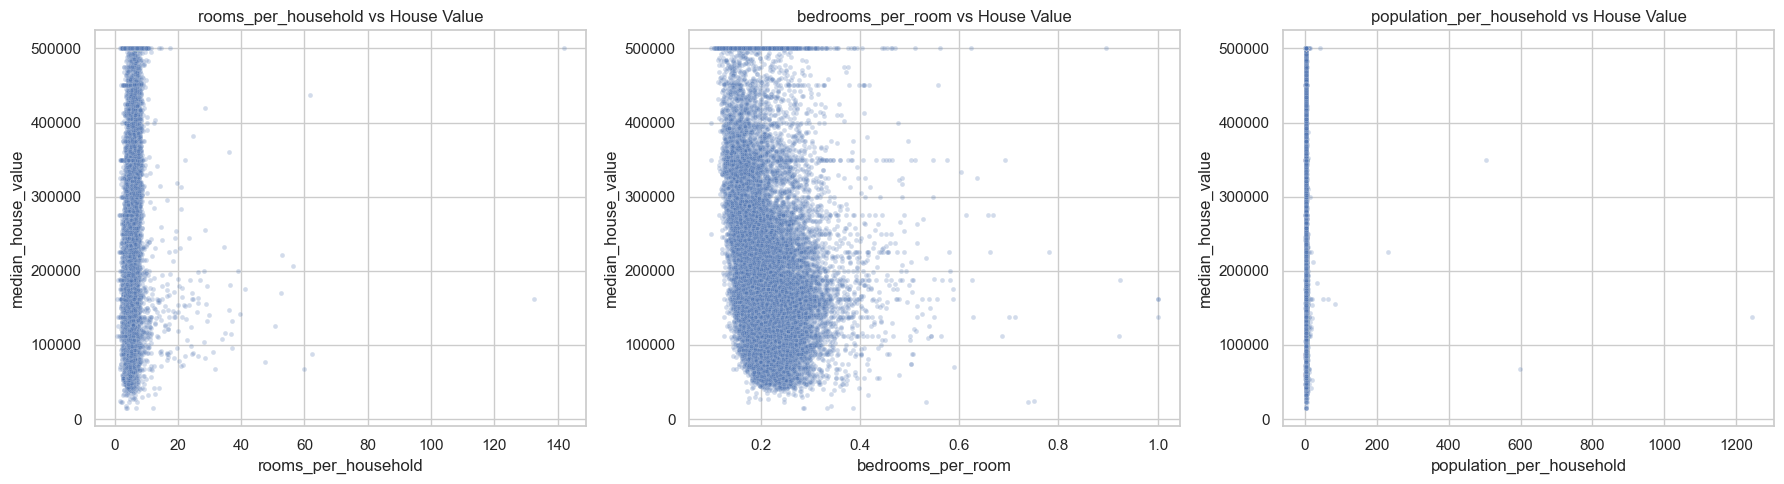

In [14]:
# Temporary analysis dataframe
analysis_housing = housing.copy()

analysis_housing["rooms_per_household"] = (
    analysis_housing["total_rooms"] / analysis_housing["households"]
)

analysis_housing["bedrooms_per_room"] = (
    analysis_housing["total_bedrooms"] / analysis_housing["total_rooms"]
)

analysis_housing["population_per_household"] = (
    analysis_housing["population"] / analysis_housing["households"]
)

ratio_features = [
    "rooms_per_household",
    "bedrooms_per_room",
    "population_per_household"
]

# Relationship between ratios and target
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, feature in zip(axes, ratio_features):
    sns.scatterplot(
        data=analysis_housing,
        x=feature,
        y=target,
        alpha=0.25,
        s=12,
        ax=ax
    )
    ax.set_title(f"{feature} vs House Value")

plt.tight_layout()
plt.show()